# Prueba  Máquinas de Aprendizaje
## Predicción del ingreso del trabajo con la ESI 2023 (INE)
**Estudiante:** Sabina ROMERO· **Archivo:** `Solemne1_Romero_Sabina.ipynb`


In [1]:
import itertools, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lasso_path
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
FIG = "figs/"
import os; os.makedirs(FIG, exist_ok=True)
DATA = "esi-2023---personas.csv"

---
# 1. Carga, descripción y limpieza (5 pts)
### 1.1 Carga

In [2]:
raw = pd.read_csv(DATA, low_memory=False)
print(f"Filas: {raw.shape[0]:,} · Columnas: {raw.shape[1]}")
print("Tipos de dato:", raw.dtypes.value_counts().to_dict())
raw[["edad", "sexo", "cine", "region", "ocup_ref", "habituales", "ing_t_t", "fact_cal_esi"]].head()

Filas: 97,998 · Columnas: 270
Tipos de dato: {dtype('float64'): 222, dtype('int64'): 37, <StringDtype(storage='python', na_value=nan)>: 11}


,edad,sexo,cine,region,ocup_ref,habituales,ing_t_t,fact_cal_esi
0,52,2,3,5,NaN,NaN,0.000,50.520
1,56,1,5,5,NaN,NaN,0.000,172.310
2,31,2,7,9,NaN,NaN,"301,323.547",150.126
3,6,1,2,13,NaN,NaN,0.000,254.718
4,64,1,7,9,1.000,4.000,"1,672,989.513",141.878


### 1.2 Definición de la población y de las variables

La base trae 270 columnas, la mayoría preguntas de flujo del cuestionario. Se seleccionan predictores con **justificación sustantiva** (teoría del capital humano, ecuación de Mincer y segmentación del mercado laboral) y se descartan explícitamente las que filtran el objetivo.

| Variable original | Variable de trabajo | Tipo | Justificación |
|---|---|---|---|
| `edad` | `edad`, `edad2` | Numérica | Perfil edad-ingreso cóncavo (experiencia potencial). |
| `sexo` | `mujer` | Binaria | Brecha de género. |
| `cine` | `educ` | Categórica ordinal (8 niveles) | Retorno a la educación. Código 999 = ignorado → faltante. |
| `region` | `region` | Categórica (16) | Diferencias regionales de productividad y costo de vida. |
| `tipo` | `rural` | Binaria | `tipo == 3` (Rural) vs Ciudad / Resto de área urbana. |
| `habituales` | `horas` | Numérica | Horas habituales trabajadas: el ingreso mensual escala con la jornada. |
| `categoria_ocupacion` | `categoria` | Categórica (7) | Asalariado privado/público, cuenta propia, empleador, servicio doméstico. |
| `ocup_form` | `informal` | Binaria | Segmentación formal/informal. |
| `b1` | `ocupacion` | Categórica (CIUO-08, 10 grupos) | Tipo de ocupación. Código 10 = "Otros no identificados"; 999 = sin clasificación → faltante. |
| `nacionalidad` | `extranjero` | Binaria | `nacionalidad != 152` (Chile). |

**Excluidas por fuga de información:** `ing_t_d`, `ing_t_i`, `ing_t_i_ai`, `ing_t_p`, `ing_t_t_ai`, `ss_t`, `svar_t`, `reg_t`, `gan_t`, `autoconsumo_t`, `ahorroimp_t`, `ing_ot`, todos los `d*_monto`, `d*_promedio`, `imp_*`, además de `tim` (tramos de ingreso del trabajo principal) e `id_mediana`. Son componentes, imputaciones o recodificaciones del propio ingreso.

> Las etiquetas y códigos de no respuesta se verificaron contra el diccionario `personas-esi-2023.pdf`; los modelos usan *one-hot*, así que el orden de los códigos no afecta las predicciones, solo la lectura de los coeficientes.

In [3]:
import re
LEAK = [c for c in raw.columns if c.startswith(("ing_", "imp_"))
        or c in {"ss_t", "svar_t", "reg_t", "gan_t", "autoconsumo_t", "ahorroimp_t", "tim", "id_mediana"}
        or re.match(r"d\d.*_(monto|montob|promedio|promediob|porcentaje)$", c)]
print(f"{len(LEAK)} columnas descartadas por fuga, p. ej.:", LEAK[:10])

REGION = {1:"Tarapacá",2:"Antofagasta",3:"Atacama",4:"Coquimbo",5:"Valparaíso",6:"O'Higgins",7:"Maule",
          8:"Biobío",9:"Araucanía",10:"Los Lagos",11:"Aysén",12:"Magallanes",13:"Metropolitana",
          14:"Los Ríos",15:"Arica y Parinacota",16:"Ñuble"}
EDUC = {1:"1 Nunca estudió",3:"3 Primaria (1)",4:"4 Primaria (2)",5:"5 Secundaria",6:"6 Técnica superior",
        7:"7 Universitaria",8:"8 Postítulo/Magíster",9:"9 Doctorado"}
CATEG = {1:"Empleador",2:"Cuenta propia",3:"Asalariado privado",4:"Asalariado público",
         5:"Serv. doméstico p. afuera",6:"Serv. doméstico p. adentro",7:"Familiar no remunerado"}
OCUP = {1:"Directores/gerentes",2:"Profesionales",3:"Técnicos",4:"Apoyo administrativo",5:"Servicios y ventas",
        6:"Agrícolas calificados",7:"Oficios y artesanos",8:"Operadores de máquinas",9:"Ocup. elementales",10:"Otros no identificados"}

pob = raw[(raw["ocup_ref"] == 1)].copy()
print(f"Ocupados: {len(pob):,} · con ing_t_t = 0: {(pob.ing_t_t == 0).sum():,}")
pob = pob[pob["ing_t_t"] > 0]

df = pd.DataFrame({
    "ing":        pob["ing_t_t"],
    "edad":       pob["edad"].astype(float),
    "mujer":      (pob["sexo"] == 2).astype(int),
    "educ":       pob["cine"].replace({999: np.nan}).map(EDUC),
    "region":     pob["region"].map(REGION),
    "rural":      (pob["tipo"] == 3).astype(int),
    "horas":      pob["habituales"].replace({0: np.nan, 888: np.nan, 999: np.nan, 8888: np.nan, 9999: np.nan}),
    "categoria":  pob["categoria_ocupacion"].map(CATEG),
    "informal":   pob["ocup_form"].map({1: 0, 2: 1}),          # 999 = sin clasificación → NaN
    "ocupacion":  pob["b1"].replace({999: np.nan}).map(OCUP),
    "extranjero": (pob["nacionalidad"] != 152).astype(int),
    "w":          pob["fact_cal_esi"],
})
print(f"Población de análisis antes de limpiar: {len(df):,}")

52 columnas descartadas por fuga, p. ej.: ['d1_monto', 'd2_1_monto', 'd2_1_porcentaje', 'd2_2_monto', 'd2_2_porcentaje', 'd2_3_monto', 'd2_3_porcentaje', 'd2_4_monto', 'd2_4_porcentaje', 'd2_5_monto']
Ocupados: 39,497 · con ing_t_t = 0: 611
Población de análisis antes de limpiar: 38,886


### 1.3 Valores faltantes

In [4]:
na = df.isna().sum().to_frame("faltantes")
na["%"] = 100 * na["faltantes"] / len(df)
display(na[na.faltantes > 0])
n0 = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Se eliminan {n0 - len(df):,} filas ({100*(n0-len(df))/n0:.2f} %). Quedan {len(df):,}.")

,faltantes,%
educ,48,0.123
horas,99,0.255
ocupacion,18,0.046


Se eliminan 157 filas (0.40 %). Quedan 38,729.


**Decisión:** eliminación por lista (*listwise deletion*). Se justifica porque los faltantes son < 1 % y corresponden a códigos de no respuesta (999) dispersos; imputar agregaría supuestos sin ganancia apreciable. Si superaran ~5 % habría que evaluar si son *MAR* e imputar dentro del pipeline de validación cruzada para no filtrar información.

### 1.4 Estadísticos descriptivos

In [5]:
num = ["ing", "edad", "horas"]
desc = df[num].describe(percentiles=[.1, .25, .5, .75, .9, .99]).T
desc["asimetría"] = df[num].skew()
display(desc)

def wq(x, w, q):
    o = np.argsort(x.values); cw = np.cumsum(w.values[o]); return x.values[o][np.searchsorted(cw, q * cw[-1])]
print(f"Mediana muestral del ingreso:   ${df.ing.median():>12,.0f}")
print(f"Mediana poblacional (factor):   ${wq(df.ing, df.w, .5):>12,.0f}")
print(f"Media muestral del ingreso:     ${df.ing.mean():>12,.0f}")

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max,asimetría
ing,"38,729.000","745,902.387","865,648.012","2,000.000","180,794.128","390,000.000","510,000.000","843,705.931","1,488,898.198","4,000,000.000","60,246,612.620",14.261
edad,"38,729.000",44.806,13.996,15.000,26.000,33.000,44.000,56.000,63.000,76.000,93.000,0.176
horas,"38,729.000",40.277,13.654,1.000,20.000,38.000,45.000,45.000,48.000,84.000,168.000,-0.257


Mediana muestral del ingreso:   $     510,000
Mediana poblacional (factor):   $     595,559
Media muestral del ingreso:     $     745,902


In [6]:
for c in ["mujer", "rural", "informal", "extranjero"]:
    print(f"{c:<11} proporción = {df[c].mean():.3f}")
for c in ["educ", "categoria", "ocupacion"]:
    t = df.groupby(c)["ing"].agg(n="size", mediana="median").sort_values("mediana")
    t["%"] = 100 * t["n"] / len(df)
    display(t.style.format({"mediana": "${:,.0f}", "%": "{:.1f}"}).set_caption(c))

mujer       proporción = 0.448
rural       proporción = 0.204
informal    proporción = 0.287
extranjero  proporción = 0.060


,n,mediana,%
educ,,,
1 Nunca estudió,197,"$301,300",0.5
3 Primaria (1),2380,"$366,269",6.1
4 Primaria (2),3791,"$436,743",9.8
5 Secundaria,16660,"$482,118",43.0
6 Técnica superior,5475,"$595,559",14.1
7 Universitaria,8921,"$900,000",23.0
8 Postítulo/Magíster,1183,"$1,652,257",3.1
9 Doctorado,122,"$2,071,122",0.3


,n,mediana,%
categoria,,,
Familiar no remunerado,25,"$150,626",0.1
Serv. doméstico p. afuera,971,"$287,854",2.5
Cuenta propia,8747,"$301,176",22.6
Serv. doméstico p. adentro,108,"$450,000",0.3
Asalariado privado,21875,"$552,427",56.5
Asalariado público,5699,"$803,529",14.7
Empleador,1304,"$873,544",3.4


,n,mediana,%
ocupacion,,,
Agrícolas calificados,1484,"$397,040",3.8
Ocup. elementales,7281,"$426,817",18.8
Servicios y ventas,8309,"$451,985",21.5
Oficios y artesanos,4925,"$496,299",12.7
Operadores de máquinas,3272,"$595,559",8.4
Apoyo administrativo,1819,"$595,559",4.7
Técnicos,4557,"$700,000",11.8
Profesionales,5552,"$1,091,859",14.3
Otros no identificados,146,"$1,200,000",0.4


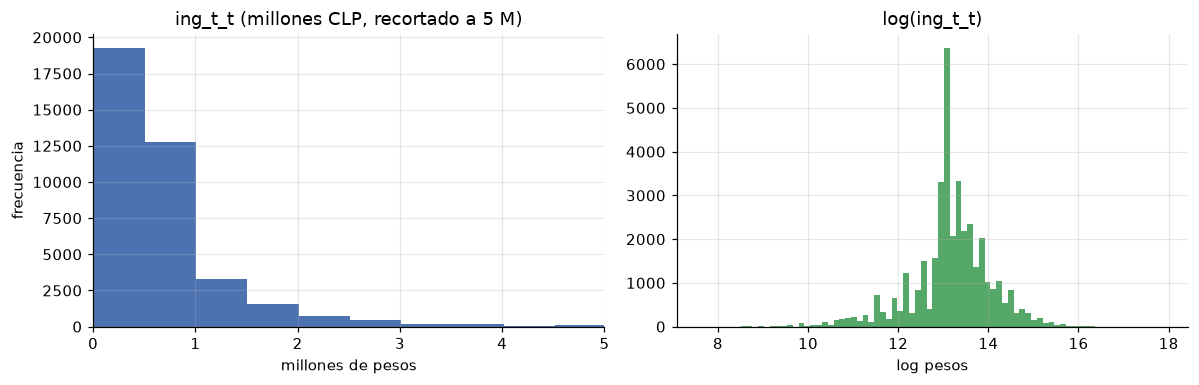

Asimetría: ingreso = 14.3 · log(ingreso) = -0.64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df.ing / 1e6, bins=120, color="#4C72B0"); ax[0].set_xlim(0, 5)
ax[0].set(title="ing_t_t (millones CLP, recortado a 5 M)", xlabel="millones de pesos", ylabel="frecuencia")
ax[1].hist(np.log(df.ing), bins=80, color="#55A868")
ax[1].set(title="log(ing_t_t)", xlabel="log pesos")
plt.tight_layout(); plt.savefig(FIG + "f1_distribucion.png", dpi=150); plt.show()
print(f"Asimetría: ingreso = {df.ing.skew():.1f} · log(ingreso) = {np.log(df.ing).skew():.2f}")

**Lectura.** El ingreso tiene asimetría positiva extrema (cola de ingresos muy altos), la media supera largamente a la mediana y la mediana ponderada por `fact_cal_esi` difiere de la muestral: la muestra no es auto-ponderada. El logaritmo deja una distribución casi simétrica, lo que justifica modelar `log(ing)`. Se observa además *heaping* en valores no redondos (p. ej. \$496 299, \$456 595, \$595 559 con cientos de casos cada uno), compatible con imputación del INE por tramos de ingreso: es ruido que ningún predictor puede explicar. Los valores extremos **no se eliminan**: son ingresos reales y en escala log dejan de dominar el ajuste.

> **Sobre el factor de expansión:** los modelos se entrenan sin ponderar porque el objetivo es *predicción*, no estimar parámetros poblacionales. Para afirmaciones descriptivas sobre Chile (por ejemplo, la mediana nacional) sí se usa `fact_cal_esi`.

In [8]:
df.drop(columns="w").to_csv("ingresos_chile_2023.csv", index=False)
print("Exportado ingresos_chile_2023.csv:", df.shape)

Exportado ingresos_chile_2023.csv: (38729, 12)


---
# 2. Modelos de regresión (15 pts)
### 2.0 Preparación: matriz de diseño, partición y modelo base

- Se crean `edad2 = edad²` (concavidad del perfil edad-ingreso) y variables *dummy* con categoría de referencia (`drop_first`).
- Cada variable original forma un **grupo** de columnas: la selección de subconjuntos opera sobre grupos, de modo que una variable categórica entra o sale completa (no tiene sentido incluir "Región de Aysén" sin el resto de las regiones).
- La estandarización para Ridge/Lasso se ajusta **solo con el fold de entrenamiento** dentro de la validación cruzada.

In [9]:
GROUPS_RAW = {
    "edad (cuadrática)": ["edad", "edad2"], "mujer": ["mujer"], "educ": None, "region": None,
    "rural": ["rural"], "horas": ["horas"], "categoria": None, "informal": ["informal"],
    "ocupacion": None, "extranjero": ["extranjero"],
}
d = df.copy(); d["edad2"] = d["edad"] ** 2
cat_cols = ["educ", "region", "categoria", "ocupacion"]
ref = {"educ": "5 Secundaria", "region": "Metropolitana", "categoria": "Asalariado privado", "ocupacion": "Ocup. elementales"}
for c in cat_cols:
    d[c] = pd.Categorical(d[c], categories=[ref[c]] + sorted(set(d[c]) - {ref[c]}))
X_all = pd.get_dummies(d[["edad", "edad2", "mujer", "rural", "horas", "informal", "extranjero"] + cat_cols],
                       columns=cat_cols, drop_first=True, dtype=float)
GROUPS = {g: (cols if cols else [c for c in X_all.columns if c.startswith(g + "_")]) for g, cols in GROUPS_RAW.items()}
y_all = np.log(df["ing"].values)
print("Predictores (columnas):", X_all.shape[1], "· grupos:", len(GROUPS))
print({g: len(c) for g, c in GROUPS.items()})

X_tr, X_te, y_tr, y_te, ing_tr, ing_te = train_test_split(
    X_all, y_all, df["ing"].values, test_size=0.20, random_state=SEED)
print(f"Entrenamiento: {len(X_tr):,} · Prueba (hold-out 20 %): {len(X_te):,}")
cols = list(X_all.columns)

Predictores (columnas): 44 · grupos: 10
{'edad (cuadrática)': 2, 'mujer': 1, 'educ': 7, 'region': 15, 'rural': 1, 'horas': 1, 'categoria': 6, 'informal': 1, 'ocupacion': 9, 'extranjero': 1}
Entrenamiento: 30,983 · Prueba (hold-out 20 %): 7,746


### 2.0.1 Validación simple vs k-fold sobre el modelo base (indicador 2.1)

Antes de comparar modelos hay que saber **qué tan confiable es la estimación del error**. Se estima el RMSE (escala log) de una regresión OLS con todos los predictores de dos formas, repitiendo cada procedimiento con 30 semillas distintas:
- **Validación simple:** una sola partición 80/20 del conjunto de entrenamiento.
- **10-fold CV.**

In [10]:
def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
Xtr_np, ytr = X_tr.values, y_tr

simple, kfold = [], []
for s in range(30):
    a, b, ya, yb = train_test_split(Xtr_np, ytr, test_size=.2, random_state=s)
    simple.append(rmse(yb, LinearRegression().fit(a, ya).predict(b)))
    errs = []
    for tr, va in KFold(10, shuffle=True, random_state=s).split(Xtr_np):
        errs.append(rmse(ytr[va], LinearRegression().fit(Xtr_np[tr], ytr[tr]).predict(Xtr_np[va])))
    kfold.append(np.mean(errs))
base_rmse = rmse(ytr, np.full_like(ytr, ytr.mean()))
cmp = pd.DataFrame({"Validación simple": simple, "10-fold CV": kfold}).agg(["mean", "std", "min", "max"]).T
display(cmp)
print(f"Modelo nulo (predice la media): RMSE log = {base_rmse:.3f}")
print(f"La desviación de la estimación con validación simple es {cmp.loc['Validación simple','std']/cmp.loc['10-fold CV','std']:.1f} veces la de 10-fold.")

,mean,std,min,max
Validación simple,0.569,0.008,0.556,0.587
10-fold CV,0.566,0.000,0.566,0.567


Modelo nulo (predice la media): RMSE log = 0.881
La desviación de la estimación con validación simple es 66.8 veces la de 10-fold.


**Lectura.** Ambos procedimientos estiman en promedio el mismo error, pero la validación simple es mucho más **inestable**: depende de qué observaciones caen en el 20 % de validación. Por eso todas las decisiones de hiperparámetros siguientes se toman con k-fold (k = 10 para regularización; k = 5 para la búsqueda exhaustiva de subconjuntos, por costo computacional). El hold-out de prueba se reserva solo para la evaluación final.

### 2.(a) Selección del mejor subconjunto (*best subsets*)

Con 10 grupos hay $2^{10}-1 = 1\,023$ modelos posibles. Se sigue el procedimiento correcto de ISLR (cap. 6.1) para no sesgar la estimación del error:

1. En **cada fold**, para cada tamaño $k = 1,\dots,10$, se elige el subconjunto con menor RSS de **entrenamiento del fold**.
2. Ese ganador se evalúa en el fold de validación.
3. Se promedia el error de validación por tamaño $k$ → curva CV(k) con su error estándar.
4. Se elige $k^*$ con la **regla 1-SE** y, finalmente, el mejor subconjunto de tamaño $k^*$ se reajusta con todo el entrenamiento.

Para que la búsqueda sea rápida se resuelven las ecuaciones normales a partir de $X^\top X$ precalculada (cada modelo es un sistema lineal pequeño).

In [11]:
gnames = list(GROUPS)
gidx = {g: [cols.index(c) for c in GROUPS[g]] for g in gnames}
subsets = [s for k in range(1, len(gnames) + 1) for s in itertools.combinations(gnames, k)]
print("Subconjuntos evaluados por fold:", len(subsets))

def fit_ne(G, b, idx):
    return np.linalg.solve(G[np.ix_(idx, idx)], b[idx])

def add_const(A): return np.column_stack([np.ones(len(A)), A])
K_BS = 5
t0 = time.time()
fold_res = []   # (fold, k, subset, train_rmse, val_rmse)
all_cv = {s: [] for s in subsets}
for f, (tr, va) in enumerate(KFold(K_BS, shuffle=True, random_state=SEED).split(Xtr_np)):
    A, Av = add_const(Xtr_np[tr]), add_const(Xtr_np[va])
    G, b, yy = A.T @ A, A.T @ ytr[tr], ytr[tr] @ ytr[tr]
    for s in subsets:
        idx = [0] + [i + 1 for g in s for i in gidx[g]]
        beta = fit_ne(G, b, idx)
        rss = yy - 2 * beta @ b[idx] + beta @ G[np.ix_(idx, idx)] @ beta
        v = rmse(ytr[va], Av[:, idx] @ beta)
        fold_res.append((f, len(s), s, np.sqrt(rss / len(tr)), v)); all_cv[s].append(v)
print(f"Búsqueda exhaustiva: {len(fold_res):,} ajustes en {time.time()-t0:.1f} s")

fr = pd.DataFrame(fold_res, columns=["fold", "k", "subset", "train_rmse", "val_rmse"])
best_per_fold = fr.loc[fr.groupby(["fold", "k"])["train_rmse"].idxmin()]
bs_curve = best_per_fold.groupby("k").agg(cv=("val_rmse", "mean"), sd=("val_rmse", "std"), train=("train_rmse", "mean"))
bs_curve["se"] = bs_curve["sd"] / np.sqrt(K_BS)
k_min = bs_curve["cv"].idxmin()
umbral = bs_curve.loc[k_min, "cv"] + bs_curve.loc[k_min, "se"]
k_1se = int(bs_curve.index[bs_curve["cv"] <= umbral].min())
display(bs_curve)
print(f"k con mínimo CV = {k_min} · umbral 1-SE = {umbral:.4f} · k elegido (1-SE) = {k_1se}")

Subconjuntos evaluados por fold: 1023
Búsqueda exhaustiva: 5,115 ajustes en 7.1 s


,cv,sd,train,se
k,,,,
1,0.748,0.021,0.748,0.009
2,0.656,0.018,0.656,0.008
3,0.619,0.018,0.619,0.008
4,0.605,0.017,0.603,0.007
5,0.590,0.015,0.589,0.007
6,0.579,0.015,0.578,0.007
7,0.571,0.015,0.571,0.007
8,0.566,0.014,0.565,0.006
9,0.566,0.014,0.565,0.006


k con mínimo CV = 9 · umbral 1-SE = 0.5726 · k elegido (1-SE) = 7


In [12]:
# Reajuste en todo el entrenamiento: mejor subconjunto (mínimo RSS) de cada tamaño
A_full = add_const(Xtr_np); G_full, b_full, yy_full = A_full.T @ A_full, A_full.T @ ytr, ytr @ ytr
best_full = {}
for s in subsets:
    idx = [0] + [i + 1 for g in s for i in gidx[g]]
    beta = fit_ne(G_full, b_full, idx)
    rss = yy_full - 2 * beta @ b_full[idx] + beta @ G_full[np.ix_(idx, idx)] @ beta
    if len(s) not in best_full or rss < best_full[len(s)][1]:
        best_full[len(s)] = (s, rss)
for k in range(1, len(gnames) + 1):
    print(f"k={k:>2}: {', '.join(best_full[k][0])}")
BS_SET = best_full[k_1se][0]
BS_COLS = [c for g in BS_SET for c in GROUPS[g]]
print(f"\nModelo best subsets elegido (k={k_1se}, {len(BS_COLS)} columnas): {BS_SET}")
print("Grupos descartados:", [g for g in gnames if g not in BS_SET])

k= 1: ocupacion
k= 2: horas, ocupacion
k= 3: horas, informal, ocupacion
k= 4: horas, categoria, informal, ocupacion
k= 5: educ, horas, categoria, informal, ocupacion
k= 6: mujer, educ, horas, categoria, informal, ocupacion
k= 7: edad (cuadrática), mujer, educ, horas, categoria, informal, ocupacion
k= 8: edad (cuadrática), mujer, educ, region, horas, categoria, informal, ocupacion
k= 9: edad (cuadrática), mujer, educ, region, horas, categoria, informal, ocupacion, extranjero
k=10: edad (cuadrática), mujer, educ, region, rural, horas, categoria, informal, ocupacion, extranjero

Modelo best subsets elegido (k=7, 27 columnas): ('edad (cuadrática)', 'mujer', 'educ', 'horas', 'categoria', 'informal', 'ocupacion')
Grupos descartados: ['region', 'rural', 'extranjero']


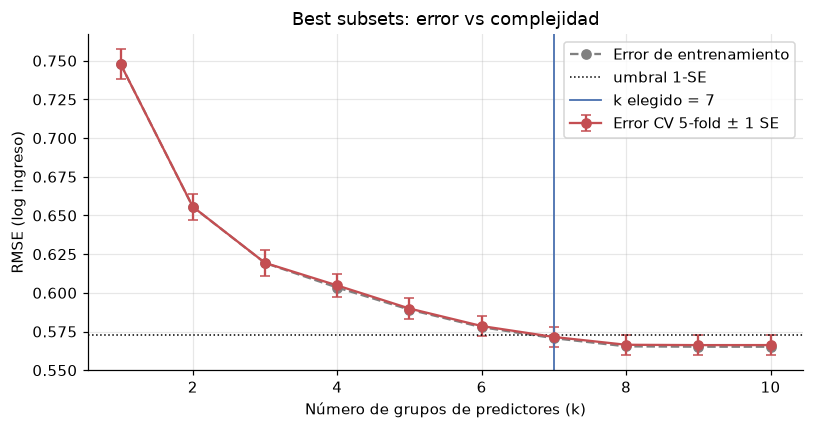

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(bs_curve.index, bs_curve.train, "o--", color="gray", label="Error de entrenamiento")
ax.errorbar(bs_curve.index, bs_curve.cv, yerr=bs_curve.se, fmt="o-", color="#C44E52", capsize=3, label="Error CV 5-fold ± 1 SE")
ax.axhline(umbral, ls=":", color="k", lw=1, label="umbral 1-SE")
ax.axvline(k_1se, color="#4C72B0", lw=1.2, label=f"k elegido = {k_1se}")
ax.set(xlabel="Número de grupos de predictores (k)", ylabel="RMSE (log ingreso)", title="Best subsets: error vs complejidad")
ax.legend(); plt.tight_layout(); plt.savefig(FIG + "f2_bestsubsets.png", dpi=150); plt.show()

### 2.(b) Regularización: Ridge y Lasso

Se recorre una grilla logarítmica de $\lambda$ (en `scikit-learn`, `alpha`). En cada uno de los 10 folds se estandariza con la media y desviación del fold de entrenamiento y se ajusta el modelo para toda la grilla. Se reporta $\lambda_{\min}$ (mínimo error CV) y $\lambda_{1SE}$ (el **mayor** $\lambda$ cuyo error no supera el mínimo + 1 SE), que es el elegido.

In [14]:
K = 10
folds = list(KFold(K, shuffle=True, random_state=SEED).split(Xtr_np))
alphas_ridge = np.logspace(-2, 5, 60)
alphas_lasso = np.logspace(0, -4, 60)          # orden decreciente (requisito de lasso_path)

def cv_curve(model, alphas):
    cv = np.zeros((K, len(alphas))); tr_err = np.zeros((K, len(alphas))); nz = np.zeros((K, len(alphas)))
    for f, (tr, va) in enumerate(folds):
        sc = StandardScaler().fit(Xtr_np[tr]); A, Av = sc.transform(Xtr_np[tr]), sc.transform(Xtr_np[va])
        if model == "lasso":
            al_ret, coefs, _ = lasso_path(A, ytr[tr] - ytr[tr].mean(), alphas=alphas)
            assert np.allclose(al_ret, alphas)          # lasso_path exige/devuelve la grilla en orden decreciente
            for j in range(len(alphas)):
                c = coefs[:, j]; mu = ytr[tr].mean()
                cv[f, j] = rmse(ytr[va], mu + Av @ c); tr_err[f, j] = rmse(ytr[tr], mu + A @ c); nz[f, j] = (c != 0).sum()
        else:
            for j, a in enumerate(alphas):
                m = Ridge(alpha=a).fit(A, ytr[tr])
                cv[f, j] = rmse(ytr[va], m.predict(Av)); tr_err[f, j] = rmse(ytr[tr], m.predict(A)); nz[f, j] = A.shape[1]
    out = pd.DataFrame({"alpha": alphas, "cv": cv.mean(0), "se": cv.std(0, ddof=1) / np.sqrt(K),
                        "train": tr_err.mean(0), "nz": nz.mean(0)})
    i_min = out.cv.idxmin(); thr = out.cv[i_min] + out.se[i_min]
    a_1se = out.loc[out.cv <= thr, "alpha"].max()
    return out, out.alpha[i_min], a_1se, thr

t0 = time.time()
ridge_cv, ridge_min, ridge_1se, ridge_thr = cv_curve("ridge", alphas_ridge)
lasso_cv, lasso_min, lasso_1se, lasso_thr = cv_curve("lasso", alphas_lasso)
print(f"CV completada en {time.time()-t0:.1f} s")
for n, cvd, amin, a1 in [("Ridge", ridge_cv, ridge_min, ridge_1se), ("Lasso", lasso_cv, lasso_min, lasso_1se)]:
    r1 = cvd.set_index("alpha").loc[a1]; r0 = cvd.set_index("alpha").loc[amin]
    print(f"{n}: λ_min = {amin:.4g} (CV {r0.cv:.4f}) · λ_1SE = {a1:.4g} (CV {r1.cv:.4f}, coef. ≠ 0 ≈ {r1.nz:.0f} de {Xtr_np.shape[1]})")

CV completada en 34.5 s
Ridge: λ_min = 0.7912 (CV 0.5661) · λ_1SE = 1661 (CV 0.5709, coef. ≠ 0 ≈ 44 de 44)
Lasso: λ_min = 0.0001 (CV 0.5661) · λ_1SE = 0.004954 (CV 0.5705, coef. ≠ 0 ≈ 41 de 44)


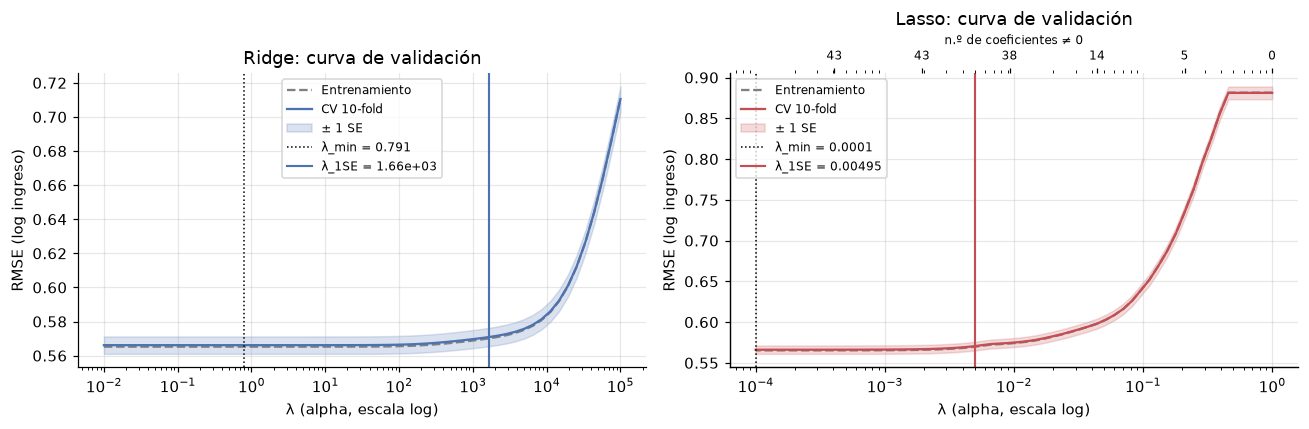

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (n, cvd, amin, a1, thr, col) in zip(axes, [("Ridge", ridge_cv, ridge_min, ridge_1se, ridge_thr, "#4C72B0"),
                                                  ("Lasso", lasso_cv, lasso_min, lasso_1se, lasso_thr, "#C44E52")]):
    ax.plot(cvd.alpha, cvd.train, "--", color="gray", label="Entrenamiento")
    ax.plot(cvd.alpha, cvd.cv, color=col, label="CV 10-fold")
    ax.fill_between(cvd.alpha, cvd.cv - cvd.se, cvd.cv + cvd.se, color=col, alpha=.2, label="± 1 SE")
    ax.axvline(amin, color="k", ls=":", lw=1, label=f"λ_min = {amin:.3g}")
    ax.axvline(a1, color=col, lw=1.4, label=f"λ_1SE = {a1:.3g}")
    ax.set_xscale("log"); ax.set(xlabel="λ (alpha, escala log)", ylabel="RMSE (log ingreso)", title=f"{n}: curva de validación")
    ax.legend(fontsize=8)
    if n == "Lasso":
        ax2 = ax.twiny(); ax2.set_xscale("log"); ax2.set_xlim(ax.get_xlim())
        ticks = cvd.alpha.values[::10]; ax2.set_xticks(ticks); ax2.set_xticklabels([f"{v:.0f}" for v in cvd.nz.values[::10]], fontsize=8)
        ax2.set_xlabel("n.º de coeficientes ≠ 0", fontsize=8); ax2.grid(False)
plt.tight_layout(); plt.savefig(FIG + "f3_curvas_lambda.png", dpi=150); plt.show()

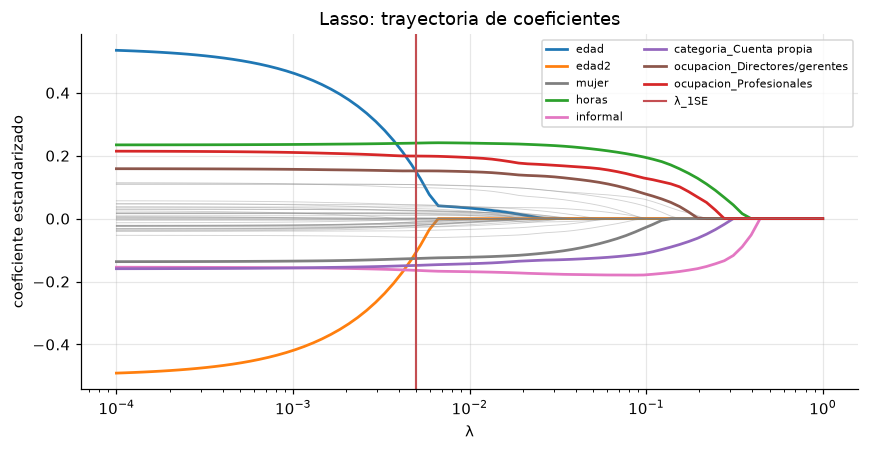

In [16]:
sc_full = StandardScaler().fit(Xtr_np); A_s = sc_full.transform(Xtr_np)
al, coefs, _ = lasso_path(A_s, ytr - ytr.mean(), alphas=np.logspace(-4, 0, 80))
fig, ax = plt.subplots(figsize=(8, 4.2))
top = np.argsort(-np.abs(coefs[:, -1]))[:8]   # 8 coeficientes más grandes con λ mínimo
pal = plt.cm.tab10.colors
for j in range(coefs.shape[0]):
    if j in top: ax.plot(al, coefs[j], lw=1.8, color=pal[list(top).index(j)], label=cols[j])
    else: ax.plot(al, coefs[j], lw=.6, color="gray", alpha=.35)
ax.axvline(lasso_1se, color="#C44E52", lw=1.4, label="λ_1SE")
ax.set_xscale("log"); ax.set(xlabel="λ", ylabel="coeficiente estandarizado", title="Lasso: trayectoria de coeficientes")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(FIG + "f4_lasso_path.png", dpi=150); plt.show()

**Cómo se eligieron los hiperparámetros.** Para best subsets, el número de grupos $k$; para Ridge y Lasso, $\lambda$. En los tres casos la curva CV es **plana cerca del mínimo**: varios valores son estadísticamente indistinguibles. La regla 1-SE resuelve ese empate eligiendo el modelo más parsimonioso (menos grupos o más penalización), lo que reduce la varianza sin pagar un costo de error medible.

---
# 3. Evaluación en el conjunto de prueba (15 pts)

Todos los modelos se reajustan con el **entrenamiento completo** y se evalúan **una sola vez** en el 20 % de prueba. Para expresar el error en pesos se retransforma con $\hat{y}_{CLP} = \exp(\hat{y}_{\log}) \cdot \hat{s}$, donde $\hat{s} = \frac{1}{n}\sum e^{\hat{\varepsilon}_i}$ es el factor de *smearing* de Duan (1983) estimado con los residuos de entrenamiento.

In [17]:
def final_models():
    sc = StandardScaler().fit(Xtr_np); A, At = sc.transform(Xtr_np), sc.transform(X_te.values)
    bs_idx = [cols.index(c) for c in BS_COLS]
    m = {}
    m["Modelo nulo (media)"] = (np.full(len(ytr), ytr.mean()), np.full(len(y_te), ytr.mean()), 0)
    ols = LinearRegression().fit(Xtr_np, ytr); m["OLS completo"] = (ols.predict(Xtr_np), ols.predict(X_te.values), Xtr_np.shape[1])
    bs = LinearRegression().fit(Xtr_np[:, bs_idx], ytr); m[f"Best subsets (k={k_1se})"] = (bs.predict(Xtr_np[:, bs_idx]), bs.predict(X_te.values[:, bs_idx]), len(bs_idx))
    for n, M, a in [("Ridge", Ridge, ridge_1se), ("Lasso", Lasso, lasso_1se)]:
        mod = M(alpha=a, max_iter=50000).fit(A, ytr)
        m[f"{n} (λ_1SE={a:.3g})"] = (mod.predict(A), mod.predict(At), int((mod.coef_ != 0).sum()))
    return m, ols

models, ols_full = final_models()
rows, preds_clp = [], {}
for n, (p_tr, p_te, npar) in models.items():
    s = np.mean(np.exp(ytr - p_tr))                 # factor smearing
    pc = np.exp(p_te) * s; preds_clp[n] = pc
    rows.append({"Modelo": n, "Predictores": npar, "Smearing": s,
                 "RMSE log": rmse(y_te, p_te), "MAE log": mean_absolute_error(y_te, p_te),
                 "R² log": 1 - np.sum((y_te - p_te) ** 2) / np.sum((y_te - y_te.mean()) ** 2),
                 "MAE (CLP)": mean_absolute_error(ing_te, pc), "RMSE (CLP)": rmse(ing_te, pc),
                 "MedAE (CLP)": np.median(np.abs(ing_te - pc))})
res = pd.DataFrame(rows).set_index("Modelo")
display(res.style.format({"Smearing": "{:.3f}", "RMSE log": "{:.4f}", "MAE log": "{:.4f}", "R² log": "{:.3f}",
                          "MAE (CLP)": "${:,.0f}", "RMSE (CLP)": "${:,.0f}", "MedAE (CLP)": "${:,.0f}"}))
res.to_csv("resultados_test.csv")

,Predictores,Smearing,RMSE log,MAE log,R² log,MAE (CLP),RMSE (CLP),MedAE (CLP)
Modelo,,,,,,,,
Modelo nulo (media),0,1.431,0.8861,0.6213,-0.000,"$457,420","$860,865","$295,745"
OLS completo,44,1.171,0.5653,0.4104,0.593,"$309,824","$691,604","$172,459"
Best subsets (k=7),27,1.175,0.5700,0.4148,0.586,"$313,769","$693,716","$174,893"
Ridge (λ_1SE=1.66e+03),44,1.173,0.5698,0.4115,0.586,"$309,125","$694,024","$172,708"
Lasso (λ_1SE=0.00495),42,1.173,0.5697,0.4116,0.587,"$310,221","$694,367","$174,600"


### 3.1 ¿Son reales las diferencias? Bootstrap pareado sobre el conjunto de prueba

Una diferencia de pocos pesos en MAE puede ser ruido muestral. Se remuestrea el conjunto de prueba 2 000 veces y se calcula el IC 95 % de la **diferencia** de MAE respecto de OLS completo (mismo remuestreo para ambos modelos: comparación pareada).

In [18]:
B = 2000; n_te = len(ing_te); ref_err = np.abs(ing_te - preds_clp["OLS completo"])
idx_b = rng.integers(0, n_te, size=(B, n_te))
boot = []
for n, pc in preds_clp.items():
    if n == "OLS completo": continue
    diff = np.abs(ing_te - pc) - ref_err
    dist = diff[idx_b].mean(1)
    boot.append({"Modelo": n, "Δ MAE vs OLS (CLP)": diff.mean(),
                 "IC95 inf": np.percentile(dist, 2.5), "IC95 sup": np.percentile(dist, 97.5)})
boot = pd.DataFrame(boot).set_index("Modelo")
boot.to_csv("bootstrap_test.csv")
boot["¿Diferencia significativa?"] = np.where((boot["IC95 inf"] > 0) | (boot["IC95 sup"] < 0), "Sí", "No")
display(boot.style.format({c: "{:,.0f}" for c in ["Δ MAE vs OLS (CLP)", "IC95 inf", "IC95 sup"]}))

,Δ MAE vs OLS (CLP),IC95 inf,IC95 sup,¿Diferencia significativa?
Modelo,,,,
Modelo nulo (media),"147,596","138,363","156,392",Sí
Best subsets (k=7),"3,945","2,383","5,566",Sí
Ridge (λ_1SE=1.66e+03),-699,"-1,928",631,No
Lasso (λ_1SE=0.00495),398,-844,"1,659",No


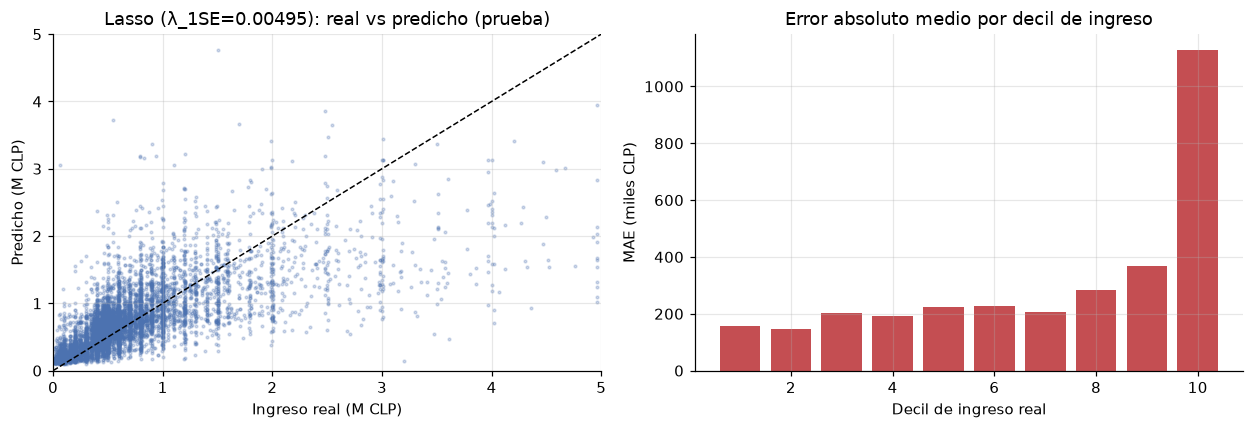

{1: 158.0, 2: 146.0, 3: 202.0, 4: 191.0, 5: 223.0, 6: 227.0, 7: 208.0, 8: 285.0, 9: 367.0, 10: 1127.0}


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
best_name = [n for n in preds_clp if n.startswith("Lasso")][0]
pc = preds_clp[best_name]
ax[0].scatter(ing_te / 1e6, pc / 1e6, s=3, alpha=.25, color="#4C72B0")
ax[0].plot([0, 5], [0, 5], "k--", lw=1); ax[0].set(xlim=(0, 5), ylim=(0, 5), xlabel="Ingreso real (M CLP)", ylabel="Predicho (M CLP)",
                                                title=f"{best_name}: real vs predicho (prueba)")
dec = pd.qcut(ing_te, 10, labels=False)
err_dec = pd.DataFrame({"dec": dec + 1, "ae": np.abs(ing_te - pc)}).groupby("dec").ae.mean() / 1e3
ax[1].bar(err_dec.index, err_dec.values, color="#C44E52")
ax[1].set(xlabel="Decil de ingreso real", ylabel="MAE (miles CLP)", title="Error absoluto medio por decil de ingreso")
plt.tight_layout(); plt.savefig(FIG + "f5_test.png", dpi=150); plt.show()
print((err_dec.round(0)).to_dict())

### 3.2 Comentario de los resultados

1. **Los cuatro modelos lineales son prácticamente equivalentes.** RMSE log entre 0,565 y 0,570 y R² ≈ 0,59. Frente al modelo nulo, el MAE baja de \$457 mil a ≈ \$310 mil (−32 %).
2. **OLS completo obtiene el menor error de prueba** y la regularización no lo mejora. El bootstrap pareado lo confirma: Ridge (−\$699) y Lasso (+\$398) tienen IC 95 % que **incluyen el cero**, es decir, no hay diferencia real. Best subsets es estadísticamente peor (+\$3 945; IC 95 % \$2 383–\$5 566), pero la diferencia es del 1,3 % del MAE y a cambio usa 27 columnas en vez de 44 (excluye región, ruralidad y nacionalidad).
3. **¿Por qué la regularización no ayuda aquí?** Hay ≈ 700 observaciones por coeficiente (30 983 / 44). Con esa razón la varianza de OLS ya es mínima: el error de entrenamiento (0,565) y el de CV (0,566) casi coinciden. El 41 % de varianza no explicada es **sesgo por variables omitidas** (tamaño de empresa, experiencia efectiva, productividad) más ruido irreducible, y eso no se corrige penalizando coeficientes.
4. **MAE vs RMSE.** El RMSE en pesos (≈ \$690 mil) es más del doble del MAE porque lo dominan los ingresos altos. En el decil 10 el error absoluto medio es ≈ \$1,1 millones, contra \$150–370 mil en los deciles 1 a 9. Al modelar en log se comprime la cola superior y el modelo subestima los ingresos altos. Por eso conviene reportar también el error mediano (MedAE ≈ \$172 mil), que describe mejor el error típico.
5. **Smearing.** El factor ≈ 1,17 indica que sin corrección las predicciones en pesos serían, en promedio, 17 % más bajas que lo correcto.

**Elección:** si el objetivo es predecir, OLS o Ridge(λ_1SE) dan el mismo rendimiento. Si se prioriza la parsimonia y la comunicación, best subsets con k = 7 pierde solo 1,3 % de precisión y deja fuera tres grupos de variables.

---
# 4. Curva de validación y compromiso sesgo-varianza (5 pts)

Las figuras de las secciones 2.(a) y 2.(b) ya son curvas de validación. A continuación se interpretan y, como en este problema $n \gg p$ (≈ 30 000 observaciones para ≈ 50 coeficientes) el sobreajuste es casi invisible, se agrega un **experimento controlado** con muestras pequeñas para mostrar el fenómeno de forma explícita (indicador 2.3).

In [20]:
# Experimento: 200 muestras de n = 150 desde el entrenamiento; se compara OLS vs Ridge (λ por CV interna)
from sklearn.linear_model import RidgeCV
Xte_np = X_te.values
n_small, R = 150, 200
coef_ols, coef_ridge, err_ols, err_ridge, tr_ols, tr_ridge = [], [], [], [], [], []
for r in range(R):
    i = rng.choice(len(Xtr_np), n_small, replace=False)
    A, yA = Xtr_np[i], ytr[i]
    keep = A.std(0) > 0                                # columnas sin variación en la submuestra
    sc = StandardScaler().fit(A[:, keep]); As, Ts = sc.transform(A[:, keep]), sc.transform(Xte_np[:, keep])
    o = LinearRegression().fit(As, yA); rg = RidgeCV(alphas=np.logspace(-2, 4, 40), cv=5).fit(As, yA)
    err_ols.append(rmse(y_te, o.predict(Ts))); err_ridge.append(rmse(y_te, rg.predict(Ts)))
    tr_ols.append(rmse(yA, o.predict(As))); tr_ridge.append(rmse(yA, rg.predict(As)))
    full = lambda c: (lambda v: (v.__setitem__(keep, c), v)[1])(np.full(Xtr_np.shape[1], np.nan))
    coef_ols.append(full(o.coef_)); coef_ridge.append(full(rg.coef_))
var_ols = np.nanmean(np.nanvar(np.array(coef_ols), 0)); var_ridge = np.nanmean(np.nanvar(np.array(coef_ridge), 0))
exp_tab = pd.DataFrame({"RMSE entrenamiento": [np.mean(tr_ols), np.mean(tr_ridge)],
                        "RMSE prueba (media)": [np.mean(err_ols), np.mean(err_ridge)],
                        "RMSE prueba (desv.)": [np.std(err_ols), np.std(err_ridge)],
                        "Varianza media de coeficientes": [var_ols, var_ridge]}, index=["OLS", "Ridge (CV)"])
display(exp_tab)
print(f"Ridge reduce la varianza de los coeficientes en {100*(1-var_ridge/var_ols):.0f} % y el RMSE de prueba en {100*(1-np.mean(err_ridge)/np.mean(err_ols)):.0f} %.")

,RMSE entrenamiento,RMSE prueba (media),RMSE prueba (desv.),Varianza media de coeficientes
OLS,0.473,0.675,0.030,0.011
Ridge (CV),0.516,0.639,0.018,0.001


Ridge reduce la varianza de los coeficientes en 89 % y el RMSE de prueba en 5 %.


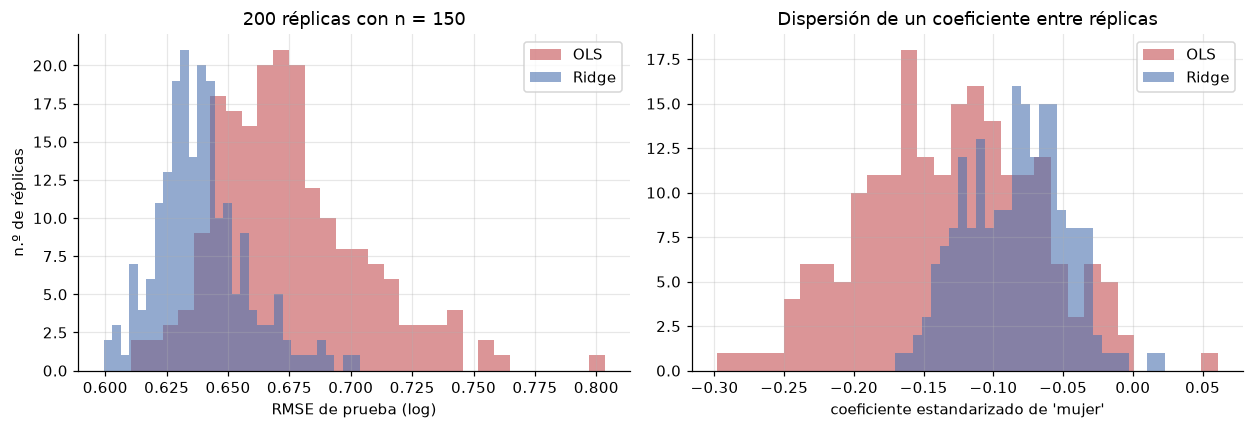

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].hist(err_ols, bins=30, alpha=.6, label="OLS", color="#C44E52"); ax[0].hist(err_ridge, bins=30, alpha=.6, label="Ridge", color="#4C72B0")
ax[0].set(xlabel="RMSE de prueba (log)", ylabel="n.º de réplicas", title=f"200 réplicas con n = {n_small}"); ax[0].legend()
j = cols.index("mujer")
ax[1].hist(np.array(coef_ols)[:, j], bins=30, alpha=.6, label="OLS", color="#C44E52")
ax[1].hist(np.array(coef_ridge)[:, j], bins=30, alpha=.6, label="Ridge", color="#4C72B0")
ax[1].set(xlabel="coeficiente estandarizado de 'mujer'", title="Dispersión de un coeficiente entre réplicas"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG + "f6_sesgo_varianza.png", dpi=150); plt.show()

### 4.1 Interpretación

**Curvas con todos los datos (figuras 2 y 3).**
- *A la izquierda* (λ pequeño o k grande) el modelo es flexible: tiene bajo sesgo y potencialmente alta varianza.
- *A la derecha* (λ grande o k pequeño) el modelo es rígido. El error de entrenamiento y el de CV **suben juntos**: eso es **sesgo** (subajuste). En el extremo, Lasso con λ ≈ 0,5 deja 0 coeficientes y reproduce el modelo nulo (RMSE 0,88).
- La curva **no muestra la "U" clásica**: es plana a la izquierda y las curvas de entrenamiento y CV se superponen. Esa brecha casi nula indica que el término de varianza es despreciable con n = 31 000, y por eso λ_min de Lasso queda en el extremo inferior de la grilla (el mejor Lasso es prácticamente OLS). La regla 1-SE elige el punto más a la derecha que todavía no se separa del mínimo.

**Experimento con n = 150 (figura 6): el fenómeno hecho visible.**

| | Entrenamiento | Prueba | Desv. prueba | Var. coeficientes |
|---|---|---|---|---|
| OLS | 0,473 | 0,675 | 0,030 | 0,011 |
| Ridge (CV) | 0,516 | 0,639 | 0,018 | 0,001 |

- OLS **sobreajusta**: hay una brecha de 0,20 entre entrenamiento y prueba.
- Ridge **sube el sesgo un poco** (+0,04 en entrenamiento) y **baja mucho la varianza**: la varianza de los coeficientes cae 89 % y la dispersión del error entre réplicas cae 40 %. El resultado neto es un error de prueba 5 % menor. Esto es lo que pide el indicador 2.3: menos varianza sin un aumento significativo de sesgo.

**¿Validación o regularización? (indicador 2.4).** No son alternativas, cumplen funciones distintas:
- La **validación cruzada** *mide* el error de generalización y *elige* hiperparámetros (λ, k).
- La **regularización** *reduce* la varianza del estimador.

La validación es indispensable siempre. La regularización vale la pena cuando p/n es alto o hay colinealidad: en la trayectoria de Lasso, `edad` y `edad²` se compensan entre sí y Lasso termina eliminando una de ellas. Con estos datos (n ≫ p) basta OLS validado por CV. En muestras pequeñas o con muchas interacciones, Ridge/Lasso serían necesarios.

---
# 5. Conclusiones y recomendaciones de política pública (20 pts)

Para fundamentar las conclusiones se interpretan los coeficientes del modelo **OLS completo** (sin penalización, para que el efecto no esté encogido). Como el objetivo está en log, $100\,(e^{\beta}-1)$ es el cambio porcentual del ingreso manteniendo constante el resto.

In [22]:
co = pd.Series(ols_full.coef_, index=cols)
eff = (100 * (np.exp(co) - 1)).rename("efecto %")
sel = ["mujer", "informal", "extranjero", "rural"] + [c for c in cols if c.startswith(("educ_", "categoria_"))]
display(eff[sel].sort_values().to_frame().style.format("{:+.1f} %"))
reg = eff[[c for c in cols if c.startswith("region_")]].sort_values()
print("Regiones (vs Metropolitana):", reg.round(1).to_dict())
age_peak = -co["edad"] / (2 * co["edad2"]); print(f"Edad de ingreso máximo (ceteris paribus): {age_peak:.0f} años")
print(f"Elasticidad aprox. por hora adicional: {100*(np.exp(co['horas'])-1):.2f} % por hora")

,efecto %
categoria_Familiar no remunerado,-53.4 %
categoria_Cuenta propia,-31.7 %
informal,-28.9 %
educ_1 Nunca estudió,-27.6 %
mujer,-24.1 %
educ_3 Primaria (1),-19.8 %
educ_4 Primaria (2),-12.6 %
categoria_Serv. doméstico p. afuera,-3.3 %
rural,-0.5 %
extranjero,+7.2 %


Regiones (vs Metropolitana): {'region_Araucanía': -16.1, 'region_Ñuble': -15.9, 'region_Arica y Parinacota': -13.8, 'region_Coquimbo': -13.3, 'region_Maule': -12.2, 'region_Biobío': -11.4, 'region_Los Ríos': -10.5, "region_O'Higgins": -9.4, 'region_Valparaíso': -7.4, 'region_Los Lagos': -5.5, 'region_Tarapacá': -0.3, 'region_Atacama': 1.3, 'region_Magallanes': 5.7, 'region_Antofagasta': 9.6, 'region_Aysén': 10.0}
Edad de ingreso máximo (ceteris paribus): 51 años
Elasticidad aprox. por hora adicional: 1.73 % por hora


### 5.1 Conclusiones

1. **Qué trabajo se hace pesa más que quién lo hace.** Best subsets incorpora primero la ocupación, después las horas y la informalidad. Con solo esas tres variables se alcanza ~85 % del poder predictivo del modelo completo (R² log ≈ 0,59).
2. **Brecha de género no explicada de 24 %.** A igual edad, educación, horas, ocupación, categoría y región, las mujeres perciben en promedio 24 % menos.
3. **El retorno a la educación es convexo y desigual.** Respecto de secundaria, la técnica superior agrega solo +9 %, la universitaria +30 %, el magíster +88 % y el doctorado +128 %.
4. **Informalidad y cuenta propia penalizan por sí mismas** (−29 % y −32 %), incluso controlando por educación y ocupación.
5. **Existe heterogeneidad territorial:** Araucanía y Ñuble están ≈ 16 % bajo la RM, mientras que Antofagasta y Aysén están ≈ 10 % sobre ella.

*Advertencia:* son asociaciones condicionales, no efectos causales. Además, el modelo deja sin explicar el 41 % de la varianza.

### 5.2 Recomendaciones de política pública

1. **Fiscalizar la igualdad salarial con datos.** Conviene complementar la Ley 20.348 con reportes obligatorios de brecha salarial por cargo en empresas medianas y grandes, y con corresponsabilidad en el cuidado infantil.
2. **Hacer conveniente la formalización.** Un régimen tributario y previsional simplificado para trabajadores por cuenta propia, junto con acceso a crédito condicionado a cotizar, podría reducir la penalización del 29–32 %.
3. **Revisar la calidad y pertinencia de la educación técnica superior.** Un retorno de solo 9 % sugiere un desajuste con la demanda laboral. Se recomienda vincular el financiamiento de los programas con la empleabilidad y los ingresos de sus egresados.

---
### Anexo: correspondencia con los indicadores de logro

| Indicador | Dónde se evidencia |
|---|---|
| 2.1 Validación simple y k-fold en modelo base | Sección 2.0.1 (comparación de estabilidad con 30 semillas). |
| 2.2 Ridge/Lasso, curva error-λ, regla 1-SE | Sección 2.(b), figura de curvas de validación. |
| 2.3 Reducción de varianza sin aumento significativo de sesgo | Sección 4, experimento con n = 150. |
| 2.4 Fundamentar validación vs regularización | Comentarios de las secciones 3 y 4. |

**Reproducibilidad:** `random_state = 42` en todas las particiones; versiones: ver celda siguiente.

In [23]:
import sklearn, sys
print("Python", sys.version.split()[0], "· pandas", pd.__version__, "· numpy", np.__version__, "· scikit-learn", sklearn.__version__)

Python 3.12.10 · pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1
